Libraries

In [1]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
torch.manual_seed(47)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


Data

In [2]:
train_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    download=True,
    train=True,
    transform=torchvision.transforms.ToTensor()
)

test_dataset = torchvision.datasets.FashionMNIST(
    root='./data',
    download=True,
    train=False,
    transform=torchvision.transforms.ToTensor()
)

torch.Size([60000, 28, 28])


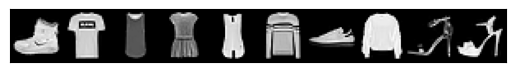

In [3]:
# sphinx_gallery_thumbnail_path = "../../gallery/assets/visualization_utils_thumbnail.png"

import torch
import numpy as np
import matplotlib.pyplot as plt

import torchvision.transforms.functional as F

plt.rcParams["savefig.bbox"] = 'tight'

def show(imgs):
    if not isinstance(imgs, list):
        imgs = [imgs]
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False)
    for i, img in enumerate(imgs):
        img = img.detach()
        img = F.to_pil_image(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

grid = torchvision.utils.make_grid(train_dataset.data[:10].unsqueeze(dim=1), nrow=10)
show(grid)

print(train_dataset.data.shape)

Model

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, stride=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=4, out_channels=16, kernel_size=3, stride=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(in_features=16*5*5, out_features=256)
        self.fc2 = nn.Linear(in_features=256, out_features=64)
        self.out = nn.Linear(in_features=64, out_features=10)

    def forward(self, x):
        x = self.conv1(x)
        x = torch.relu(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = torch.relu(x)
        x = self.pool2(x)

        x = torch.flatten(x, start_dim=1)

        x = self.fc1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        x = torch.relu(x)
        x = self.out(x)
        return x

Training loop

In [10]:
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size = 128
)

lr = 0.02
n_epochs = 40
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

if device != torch.device('cpu'):
    model.to(device)

for epoch in range(n_epochs):
    for i, (X, y) in enumerate(train_dataloader):
        if device != torch.device('cpu'):
            X, y = X.to(device), y.to(device)

        y_pred = model(X)
        loss = criterion(y_pred, y)
        loss.backward()
        optimizer.step()

        optimizer.zero_grad()

    print(f"Epoch: {epoch}; Loss: {loss:.5f}")

Epoch: 0; Loss: 1.18804
Epoch: 1; Loss: 0.75890
Epoch: 2; Loss: 0.63356
Epoch: 3; Loss: 0.55071
Epoch: 4; Loss: 0.48389
Epoch: 5; Loss: 0.44395
Epoch: 6; Loss: 0.42116
Epoch: 7; Loss: 0.40091
Epoch: 8; Loss: 0.38823
Epoch: 9; Loss: 0.37444
Epoch: 10; Loss: 0.36422
Epoch: 11; Loss: 0.35436
Epoch: 12; Loss: 0.34714
Epoch: 13; Loss: 0.33842
Epoch: 14; Loss: 0.33464
Epoch: 15; Loss: 0.33168
Epoch: 16; Loss: 0.32482
Epoch: 17; Loss: 0.32220
Epoch: 18; Loss: 0.31962
Epoch: 19; Loss: 0.31548
Epoch: 20; Loss: 0.30981
Epoch: 21; Loss: 0.30398
Epoch: 22; Loss: 0.29999
Epoch: 23; Loss: 0.29780
Epoch: 24; Loss: 0.29060
Epoch: 25; Loss: 0.28579
Epoch: 26; Loss: 0.27765
Epoch: 27; Loss: 0.27111
Epoch: 28; Loss: 0.26701
Epoch: 29; Loss: 0.26134
Epoch: 30; Loss: 0.25238
Epoch: 31; Loss: 0.24989
Epoch: 32; Loss: 0.24389
Epoch: 33; Loss: 0.24022
Epoch: 34; Loss: 0.23086
Epoch: 35; Loss: 0.22547
Epoch: 36; Loss: 0.22402
Epoch: 37; Loss: 0.21703
Epoch: 38; Loss: 0.21725
Epoch: 39; Loss: 0.21256


Test

In [13]:
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size = 128
)

def evaluate(model, loader):
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            total_loss += criterion(y_pred, y).item()
            correct += (y_pred.argmax(dim=1) == y).sum().item()

    return total_loss / len(loader), correct / len(loader.dataset)

print(evaluate(model, test_dataloader))

(0.32523111404874655, 0.8838)
